# Detecting designed proteins — ProteinMPNN and relatives

**Runtime → Run all.** Nothing to upload. With `THOROUGH = True` (the default)
expect **20–45 minutes** on a free CPU runtime; set it to `False` for a ~5 minute
pass.

This screens protein sequences for signs of having been produced by a sequence
design model (ProteinMPNN, LigandMPNN, ESM-IF) rather than by evolution.

### Why the two-HMM approach it replaces could not work

The earlier version built two profile HMMs — one from a natural family, one from
a set of designed proteins — and classified on the difference in bit scores.

A profile HMM models the conserved positions of **one family**, and "designed"
is not a family. The designed model came from an alignment of Top7, a 3-helix
bundle and a TIM barrel: three unrelated folds, so the profile had no
information content. Its demo "worked" because the query *was* Top7.

Worse, it failed where it was needed. A ProteinMPNN redesign keeps the fold and
30–50% identity to its parent, so it scores **high** on the natural profile and
**zero** on any designed profile — every real variant would have been called
NATURAL.

### What this does instead

Four layers, each harder to defeat than the last:

| Layer | Asks | Cost |
|---|---|---|
| **Composition** | Does residue usage match the generator rather than this family? | free |
| **Structural residual** | Is the buried core preserved while the surface is rewritten? | cheap |
| **Direct couplings (DCA)** | Does it satisfy position pairs this family couples? | a matrix inversion |
| **Phylogenetic** | Could it have *descended* from this family's tree? | a tree per query |

The deep layers are the point. Composition fingerprints are defeated by raising
sampling temperature; a Potts model and a phylogenetic placement are not. There
are cells below that demonstrate both.

### What changed in this version

* **Fixed the retrieval bug behind the last run.** UniProt bodies came back
  gzipped *twice*; one decompression left them still compressed, and the
  compressed bytes were decoded as text. That is why the run reported
  "retrieved 14, 14 unusable" and fell back to a simulated family. The garbage
  was also **cached to Drive**, so it would have persisted. Both fixed, and the
  cache key is versioned so the poisoned entry is retired.
* **Mutual information replaced by mean-field DCA.** MI counts correlations that
  run through a third position; DCA conditions them away.
* **Nearest-neighbour comparisons replaced by phylogenetic placement.** The
  query is placed against an *inferred ancestor* of its local subtree, not
  against one diverged cousin.
* **Repeated-split validation.** Every number below now comes with an interval
  across independent rebuilds, and a permutation test per signal.

## 1. Setup


In [1]:
!pip install -q pyhmmer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 30.2 MB/s eta 0:00:00


In [ ]:
# Self-contained bootstrap: no files to upload.
# Writes a readable mpnn_detect.py into the working directory - open the
# folder icon in the left sidebar to read, edit or download the source.
import base64, gzip, pathlib, sys

_SRC = (
    "..."
)

pathlib.Path('mpnn_detect.py').write_bytes(gzip.decompress(base64.b64decode(_SRC)))
sys.path.insert(0, '.')

import mpnn_detect as md

# 22 signals are defined; one (comp_llr_background) is superseded once a
# family profile exists, because composition is then compared against the
# family rather than the global background. So 21 are scored below.
_superseded = sum(1 for f in md.FEATURE_SPECS if f.superseded_by_profile)
print(f'mpnn_detect {md.__version__} | pyhmmer: {md.HAVE_PYHMMER} | '
      f'{len(md.FEATURE_KEYS)} signals '
      f'({len(md.FEATURE_KEYS) - _superseded} scored with a family profile)')


## 2. How hard to work


In [ ]:
#@title Run depth { display-mode: "form" }
THOROUGH = True  #@param {type:"boolean"}
#@markdown `THOROUGH` fits a Potts model (DCA) and runs repeated-split
#@markdown validation. It is the difference between a demo and a measurement.
VALIDATION_REPEATS = 8  #@param {type:"integer"}
#@markdown How many independent rebuilds to average over. Each one refits
#@markdown everything, so this is where the run time goes.

import logging, time
RUN_T0 = time.time()
COUPLING_METHOD = "dca" if THOROUGH else "mi"
# A Potts fit needs the effective sequence count to exceed the number of model
# positions by a good margin, so a thorough run also needs a bigger family.
TARGET_SEQUENCES = 6000 if THOROUGH else 600
SYMFRAC = 0.6  #@param {type:"number"}
#@markdown `SYMFRAC` keeps an alignment column as a model position only when
#@markdown this fraction of sequences occupies it. On real full-length proteins
#@markdown it is the difference between a model the length of the domain and one
#@markdown twice that: measured on 433 PF00069 kinases, 0.0 gave a 459-position
#@markdown model and 0.6 gave 314, and the structural signals roughly doubled
#@markdown in AUROC as a result.
print(f"mode: {'THOROUGH' if THOROUGH else 'quick'} | couplings={COUPLING_METHOD} "
      f"| target family size={TARGET_SEQUENCES} | symfrac={SYMFRAC} "
      f"| validation repeats={VALIDATION_REPEATS if THOROUGH else 0}")

## 3. Mount Google Drive

Everything this notebook produces goes to Drive, under
`MyDrive/<DRIVE_FOLDER>/`. Two reasons that matters on Colab:

* **Runtimes disconnect.** Building a profile on a real family takes minutes,
  and the covariation and evolutionary models take more. With the profile saved
  to Drive, a later session loads it in seconds instead of rebuilding it.
* **UniProt downloads are cached there too**, so re-running costs no network.

Approving the mount popup is interactive — Run all pauses here until you do.
If Drive is unavailable the notebook falls back to a local folder and keeps
going, so nothing below depends on it.

In [3]:
DRIVE_FOLDER = "mpnn_detect"  #@param {type:"string"}
RUN_NAME = "run1"  #@param {type:"string"}
REUSE_EXISTING = True  #@param {type:"boolean"}

import json, os, pathlib, time

ON_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = pathlib.Path("/content/drive/MyDrive") / DRIVE_FOLDER
    ON_DRIVE = True
except Exception as exc:
    ROOT = pathlib.Path("./mpnn_detect_output").resolve()
    print(f"Drive not mounted ({type(exc).__name__}: {exc})")
    print("Falling back to local storage - results will be lost when the runtime ends.")

CACHE = ROOT / "cache"           # UniProt downloads, shared across every run
OUT = ROOT / "runs" / RUN_NAME   # this run's outputs
for d in (CACHE, OUT):
    d.mkdir(parents=True, exist_ok=True)

print()
print(f"storage : {'Google Drive' if ON_DRIVE else 'local (temporary)'}")
print(f"cache   : {CACHE}")
print(f"outputs : {OUT}")
if REUSE_EXISTING and (OUT / "profile_model" / "profile.json").exists():
    print()
    print("An existing profile was found in this run folder and will be reused.")
    print("Set REUSE_EXISTING = False, or change RUN_NAME, to rebuild from scratch.")

Mounted at /content/drive

storage : Google Drive
cache   : /content/drive/MyDrive/mpnn_detect/cache
outputs : /content/drive/MyDrive/mpnn_detect/runs/run1


## 4. Get a natural family

Edit the Pfam accession below and re-run. Pfam accessions (`PF00069` = protein
kinase) are far more reliable than free-text names.

If the query matches too little, the cell retries without the reviewed-only
restriction, and if that still falls short it reports exactly where the
sequences were lost — matched, unparseable, or outside the length window — and
falls back to a simulated family so the rest of the notebook still runs. The
simulation evolves sequences along a tree with
chemistry-structured substitutions, gamma site rates, indels and coupled
position pairs — enough to exercise every signal, but **not** a substitute for
real data.

In [ ]:
FAMILY = "PF00069"  #@param {type:"string"}
NATURAL_FASTA = ""  #@param {type:"string"}
#@markdown Leave `NATURAL_FASTA` empty to fetch from UniProt. Set it to the
#@markdown path of your own FASTA to skip the network entirely - which is also
#@markdown the only way to run behind a proxy that blocks UniProt, and the only
#@markdown way to profile a family Pfam has no accession for.
MIN_LENGTH = 150  #@param {type:"integer"}
MAX_LENGTH = 400  #@param {type:"integer"}
MIN_USABLE = 120  #@param {type:"integer"}

import numpy as np

# Acquisition lives in md.assemble_family(), not in this cell. It used to live
# here, and in three separate runs it shipped three bugs that no test could
# see: a doubly-compressed response decoded as text; stopping at the reviewed
# set; and a guard for the local-file path that also matched the UniProt path,
# so the unreviewed top-up silently never ran. That last one left the previous
# run with 433 sequences against a 312-position model - which forced mutual
# information instead of DCA, and a 96-sequence null that could not place
# alpha=0.01. Reviewed entries first, then topped up, with both passes
# reported.
t0 = time.time()
acq = md.assemble_family(
    term=FAMILY,
    natural_fasta=NATURAL_FASTA or None,
    min_length=MIN_LENGTH, max_length=MAX_LENGTH,
    target=TARGET_SEQUENCES, min_usable=MIN_USABLE,
    cache_dir=str(CACHE),
)
print(acq.report())

family, SOURCE = acq.sequences, acq.source
if not family:
    print()
    print(f"Could not assemble {MIN_USABLE}+ usable sequences for '{FAMILY}'.")
    print("Using a simulated family instead - everything below is a DEMO, not a")
    print("benchmark. The simulation cannot validate any signal, only exercise it.")
    print("Section 14 will refuse to measure real designs against it, and says so.")
    family = md.dereplicate(md.simulate_natural_family(n=TARGET_SEQUENCES, seed=11),
                            identity_threshold=0.90, max_keep=TARGET_SEQUENCES)
    SOURCE = "simulated"

lengths = [len(s) for s in family]
print()
print(f"{len(family)} sequences from {SOURCE} in {time.time()-t0:.0f}s "
      f"(lengths {min(lengths)}-{max(lengths)}, median {int(np.median(lengths))})")

# Say now - before a 40-minute build - whether the family can support the alpha
# this run intends. The smallest p-value an n-sequence null can state is
# 1/(n+1); below that every call comes from a tail fit, which costs detection.
# The split cell gives the null at most 35% of the family.
TARGET_ALPHA = 0.01
needed = int(5 / TARGET_ALPHA)
projected = int(min(0.35 * len(family), max(60, needed)))
reachable = 5 / (projected + 1)
if reachable > 1.2 * TARGET_ALPHA:
    print()
    print(f"The null will hold about {projected} sequences, so the smallest "
          f"alpha it can place is ~{reachable:.3g}, not {TARGET_ALPHA}.")
    print("Raise TARGET_SEQUENCES or widen the length window to run at "
          f"{TARGET_ALPHA}; otherwise this run will adopt ~{reachable:.3g} and "
          "say so.")
else:
    print(f"The null will hold about {projected} sequences, enough to place "
          f"alpha={TARGET_ALPHA}.")

## 5. Split into three disjoint sets

This matters more than it looks. The profile, the per-family reference
distributions, and the null that sets the false-positive rate must each come
from different sequences. Reusing them makes every score look better than it is
and the threshold run loose — the detector warns you if it detects the overlap.

In [5]:
import random
# Shuffle first. Database order is never random - UniProt returns results
# grouped by organism and accession, so a positional split would put whole
# clades in one set and none in another, and every score would inherit that.
family = family[:]
random.Random(0).shuffle(family)

n = len(family)
build_set = family[: int(0.55 * n)]
ref_set   = family[int(0.55 * n) : int(0.78 * n)]
null_set  = family[int(0.78 * n) :]
print(f"build {len(build_set)}  |  reference {len(ref_set)}  |  null {len(null_set)}")
print(f"mean length  {np.mean([len(s) for s in build_set]):.0f} / "
      f"{np.mean([len(s) for s in ref_set]):.0f} / "
      f"{np.mean([len(s) for s in null_set]):.0f}  (should be similar)")

build 231  |  reference 96  |  null 93
mean length  214 / 215 / 215  (should be similar)


## 6. Build the profile

No MAFFT and no `apt-get`: a seed model from the most central sequence, then
iterative `hmmalign` and rebuild.

Four models are fitted here, and in a thorough run the last three are most of
the cost:

* the **profile HMM** itself, and which positions are buried or exposed;
* the **coupling model** — a mean-field Potts model (DCA) when there is enough
  data for one, otherwise mutual information. DCA inverts an (M × 20) square
  covariance matrix, which is the single most expensive step;
* the **evolutionary model** — the family's own exchangeability matrix, site
  rates and indel-versus-divergence curve;
* the **placement null** — for each member, the distance from the ancestor
  inferred at the root of its *own* nearest relatives, excluding itself. That
  leave-one-out construction is what makes "this sequence attaches nowhere" a
  statement with a scale behind it.

A guard refuses to build a profile over sequences that are not one family — the
failure that made the original notebook's designed model meaningless.

In [ ]:
PROFILE_DIR = OUT / "profile_model"
params = {"source": SOURCE, "n_build": len(build_set), "n_ref": len(ref_set),
          "n_null": len(null_set), "version": md.__version__,
          "couplings": COUPLING_METHOD, "symfrac": SYMFRAC}

reuse = REUSE_EXISTING and (PROFILE_DIR / "profile.json").exists()
if reuse:
    saved = json.loads((OUT / "run_info.json").read_text()) if (OUT / "run_info.json").exists() else {}
    changed = [k for k, v in params.items() if saved.get(k) not in (None, v)]
    if changed:
        print(f"Saved profile used different settings ({', '.join(changed)}); rebuilding.")
        reuse = False

t0 = time.time()
if reuse:
    profile = md.FamilyProfile.load(str(PROFILE_DIR))
    print(f"loaded saved profile from Drive in {time.time()-t0:.0f}s")
else:
    profile = md.FamilyProfile(name=SOURCE).build(
        build_set, coupling_method=COUPLING_METHOD, symfrac=SYMFRAC)
    profile.fit_feature_reference(md.extract_features, md.PROTEINMPNN_PRIOR,
                                  reference_sequences=ref_set)
    profile.save(str(PROFILE_DIR))
    print(f"built and saved in {time.time()-t0:.0f}s")

med = int(np.median([len(s) for s in build_set]))
print(f"  {profile.hmm.M} model positions, {profile.n_sequences} members "
      f"(median member {med} aa)")
if profile.meff:
    ratio = profile.meff / profile.hmm.M
    if ratio >= 2.0:
        verdict = "enough for full 20-residue DCA"
    elif ratio >= 2.0 * 7 / 20:
        verdict = "enough for reduced-alphabet DCA (7 chemical classes)"
    else:
        verdict = "too thin for any Potts fit"
    print(f"  Meff        : {profile.meff:.0f}  ->  Meff/M = {ratio:.2f}   {verdict}")
    # What it would actually take, from this family's own redundancy rather
    # than an assumed constant. Real kinases came out at Meff/n = 0.47, not the
    # 0.7 assumed earlier, which is why a 1500-sequence family still fell short.
    obs = profile.meff / max(profile.n_sequences, 1)
    if ratio < 2.0:
        need = int(2.0 * profile.hmm.M / max(obs, 0.1) / 0.55)
        print(f"                this family gives Meff/n = {obs:.2f}, so full DCA")
        print(f"                would need about {need} dereplicated sequences")
print(f"  {int(profile.buried_mask.sum())} buried / {int(profile.exposed_mask.sum())} exposed-variable")
if profile.coupling:
    c = profile.coupling
    print(f"  couplings   : {len(c['pairs'])} pairs by {c['method'].upper()} "
          f"(Meff={c['neff']:.0f}, Meff/M={c['neff']/profile.hmm.M:.1f})")
    if c["method"] == "mi":
        print("                MI counts correlations that run through a third")
        print("                position; DCA conditions them away but needs more data.")
else:
    print("  couplings   : none reliable in this family - signal disabled")
if profile.evo:
    print(f"  evolution   : {profile.evo['n_subst_pairs']} substitution pairs, "
          f"mean site rate {profile.evo['rate'].mean():.2f}")
if profile.placement:
    p = profile.placement
    print(f"  placement   : {p['n']} leave-one-out placements, real relatives sit "
          f"{p['pendant_mean']:.3f} +- {p['pendant_sd']:.3f} subs/site")
    print(f"                from their inferred ancestor")

(OUT / "run_info.json").write_text(json.dumps(
    {**params, "model_positions": int(profile.hmm.M),
     "coupled_pairs": len(profile.coupling["pairs"]) if profile.coupling else 0,
     "coupling_method": profile.coupling["method"] if profile.coupling else None,
     "on_drive": ON_DRIVE, "written": time.strftime("%Y-%m-%d %H:%M:%S")}, indent=2))

## 7. Set a false-positive rate

`P(designed)` is a ranking score — a 0.7 threshold on it means nothing in
particular, because its value depends on the intercept and on how many signals
happen to be available. The quantile of the natural score distribution means
something exact: at `alpha=0.01`, one natural sequence in a hundred is flagged,
by construction.

With only a few hundred null sequences you will see a warning that `alpha` is
below what the null can resolve: with *n* sequences the smallest p-value that
can be observed directly is 1/(n+1). Past that floor the detector extrapolates
from an exponential fit to the tail and marks the result
`[tail-extrapolated]`. That is working as intended — more null sequences make
those p-values exact rather than fitted.

In [7]:
ALPHA = 0.01  #@param {type:"number"}

DETECTOR_PATH = OUT / "detector.json"
# Only reuse a saved detector when the profile was ALSO reused. A detector
# carries a null, a threshold and per-family references that belong to one
# specific profile, and scores are not comparable across profiles - so pairing
# a saved detector with a freshly rebuilt profile silently invalidates every
# p-value below. The module now refuses the mismatch outright; this keeps the
# notebook from asking for it in the first place.
detector = None
if REUSE_EXISTING and reuse and DETECTOR_PATH.exists():
    try:
        detector = md.Detector.load(str(DETECTOR_PATH), profile=profile)
        info = detector.null_info
        print(f"loaded saved detector from {DETECTOR_PATH.name} "
              f"(null of {info.get('n')} sequences)")
    except md.ModelNotBuiltError as exc:
        print(f"saved detector does not match this profile, refitting:\n  {exc}")
        detector = None
elif REUSE_EXISTING and DETECTOR_PATH.exists():
    print("the profile was rebuilt, so the saved detector's null no longer applies"
          " - refitting")
if detector is None:
    detector = md.Detector(profile=profile, fingerprint=md.PROTEINMPNN_PRIOR, alpha=ALPHA)
    info = detector.fit_null(null_set)
    detector.fit_window_null(null_set, window=140, step=20)
    detector.save(str(DETECTOR_PATH))

# An alpha below what the null can place is not an operating point - every call
# past the empirical floor of 1/(n+1) comes from a tail fit. Measured on 433
# real kinases, running at alpha=0.01 against a 47-sequence null detected 86%
# of designs where alpha=0.05 detected 98%, for the same model. So adopt the
# reachable alpha rather than quietly running at an unreachable one.
recommended = info.get("recommended_alpha")
EFFECTIVE_ALPHA = ALPHA
if recommended and recommended > ALPHA:
    EFFECTIVE_ALPHA = round(recommended, 4)
    detector.alpha = EFFECTIVE_ALPHA
    print()
    print(f"alpha={ALPHA} needs a null of about {int(5/ALPHA)} sequences; this one has "
          f"{info['n']}.")
    print(f"Using alpha={EFFECTIVE_ALPHA} instead, which this null can actually place.")
    print("Enlarge the family to run at a smaller alpha.")

print()
print(f"null: {info.get('n')} sequences, score threshold "
      f"{info.get('threshold', float('nan')):.2f} at alpha={detector.alpha}")

WARNING mpnn_detect: alpha=0.01 is below what 93 null sequences can resolve empirically (floor 0.0108); p-values past that floor come from an exponential tail fit and are approximate. More null sequences would make them exact.
INFO mpnn_detect: Null fitted on 93 sequences; score threshold at alpha=0.01 is 6.52.
INFO mpnn_detect: Window null fitted on 372 windows (w=140, step=20).


null: 93 sequences, score threshold 6.52 at alpha=0.01

alpha=0.01 is below what 93 null sequences can resolve empirically (floor 0.0108); p-values past that floor come from an exponential tail fit and are approximate. More null sequences would make them exact.


## 8. Screen a sequence

Every verdict comes with its breakdown: which signals fired, what the family's
own value is for each, and how much the call depends on its largest contributor.
Paste your own sequence below.

In [8]:
QUERY = ""  #@param {type:"string"}

if QUERY.strip():
    query = md.clean_sequence(QUERY, name="your_sequence")
else:
    # No sequence given, so demonstrate on a simulated redesign of this family.
    query = md.simulate_designed(profile, n=1, seed=0)[0]
    print("(no sequence pasted - showing a simulated redesign of this family)\n")

result = detector.predict(query)
print(result.report())

md.write_csv(md.results_to_rows([result]), str(OUT / "query_result.csv"))

INFO mpnn_detect: Simulated 1 proteinmpnn-like redesigns.
INFO mpnn_detect: Wrote 1 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/query_result.csv


(no sequence pasted - showing a simulated redesign of this family)

sim_proteinmpnn_0000  (216 aa)
------------------------------------------------------------------
Verdict           : LIKELY DESIGNED
P(designed)       : 1.000   [UNCALIBRATED - prior weights]
p vs natural null : 1.716e-09 [tail-extrapolated]   (fraction of known-natural sequences scoring this high)
Robustness        : supported by multiple signals (largest is coupling_violation at 18%)
Closest generator : proteinmpnn (+0.062 nats/res)

Strongest signals:
  designed  +6.71  coupling_violation     raw=+7.451  (breaks position couplings that the natural family preserves)
  designed  +5.45  orphan_fold            raw=+0.505  vs family +0.298+-0.045  (matches the family fold but has no close natural relative)
  designed  +4.54  exposed_llr            raw=+0.184  vs family -0.365+-0.093  (solvent-exposed positions carry generator-typical residues)
  designed  +3.71  comp_llr_family        raw=+0.062  vs family -0.064+-0.028

'/content/drive/MyDrive/mpnn_detect/runs/run1/query_result.csv'

## 9. Screen a batch

A single borderline sequence is weak evidence. Fifty from one pipeline, each
borderline in the same direction, are not — the shared bias accumulates. The
binomial test is robust; Fisher's method uses the magnitudes but assumes
independence, which redesigns of one backbone badly violate. A wide gap between
them means the batch is internally correlated, not that the evidence is stronger.

In [9]:
designs = md.simulate_designed(profile, n=40, seed=7)
naturals = null_set[:40]

batch_designed = md.screen_batch(designs, detector)
batch_natural = md.screen_batch(naturals, detector)
print(batch_designed.report())
print()
print(batch_natural.report())

# Per-sequence table for both batches, plus the batch-level summary.
rows = (md.results_to_rows(batch_designed.results) +
        md.results_to_rows(batch_natural.results))
for row, label in zip(rows, ["designed"] * len(batch_designed.results) +
                            ["natural"] * len(batch_natural.results)):
    row["batch"] = label
# Per-sequence alpha is the wrong error rate once you screen more than a
# handful. At alpha=0.01, ten thousand natural sequences give a hundred flags
# by construction. The q-value answers what a screen actually needs to know:
# of the sequences I flag, what fraction should I expect to be wrong?
all_results = batch_designed.results + batch_natural.results
md.apply_fdr(all_results, fdr=0.05)
n_alpha = sum(1 for r in all_results if r.p_value is not None and r.p_value <= detector.alpha)
n_fdr = sum(1 for r in all_results if r.fdr_significant)
print()
print(f"  across all {len(all_results)} sequences: "
      f"{n_alpha} flagged at alpha={detector.alpha}, {n_fdr} at FDR 5%")

md.write_csv(rows, str(OUT / "screening_results.csv"))
md.write_csv([{"batch": lbl, "n": b.n, "flagged": b.n_flagged,
               "expected_flagged": round(b.expected_flagged, 2),
               "binomial_p": b.binomial_p, "fisher_p": b.fisher_p,
               "median_p_designed": round(b.median_p_designed, 4),
               "mutual_identity": round(b.mutual_identity, 3), "verdict": b.verdict}
              for lbl, b in [("designed", batch_designed), ("natural", batch_natural)]],
             str(OUT / "batch_summary.csv"))

INFO mpnn_detect: Simulated 40 proteinmpnn-like redesigns.
INFO mpnn_detect: FDR 0.05: 41 of 80 flagged (per-sequence alpha would flag 42).
INFO mpnn_detect: Wrote 80 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/screening_results.csv
INFO mpnn_detect: Wrote 2 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/batch_summary.csv


Batch of 40 sequences
------------------------------------------------------------------
Flagged                : 40 (expected 0.4 by chance)
Binomial p             : 1e-80
Fisher combined p      : 1.44e-231
Median P(designed)     : 1.000
Mutual identity        : 0.22
Verdict                : BATCH LIKELY DESIGNED

Batch of 40 sequences
------------------------------------------------------------------
Flagged                : 0 (expected 0.4 by chance)
Binomial p             : 1
Fisher combined p      : 0.603
Median P(designed)     : 0.081
Mutual identity        : 0.40
Verdict                : NO BATCH-LEVEL SIGNAL

  across all 80 sequences: 40 flagged at alpha=0.01, 41 at FDR 5%


'/content/drive/MyDrive/mpnn_detect/runs/run1/batch_summary.csv'

## 10. Localise a designed region

A whole-sequence score averages a chimera into the middle of the range. Sliding
the detector along shows where the signal actually sits: a natural domain fused
to a designed scaffold gives a gradient rather than a flat profile.

This is the weakest capability here, so it is reported as a rate over many
fusions rather than one picture. A 140-residue window carries far less evidence
than a whole sequence, and any single example can look unconvincing by chance.

In [10]:
WINDOW, STEP = 140, 20
detector.fit_window_null(null_set, window=WINDOW, step=STEP)

# Controls come from the reference split, not null_set: the window null was
# fitted on null_set, and scoring a sequence against a null it helped build
# understates how unusual it looks.
def bars(seq):
    ws = md.scan_sequence(seq, detector, WINDOW, STEP)
    return "".join("#" if (w.p_value or 1) <= 0.02 else
                   "+" if (w.p_value or 1) <= 0.15 else "." for w in ws), ws

for label, seq in [("natural", ref_set[0]), ("designed", designs[0])]:
    b, ws = bars(seq)
    print(f"  {label:<9} {b}   heterogeneity={md.signal_heterogeneity(ws):.2f}")

half = len(designs[0].seq) // 2
fusion = md.CleanSequence(seq=designs[0].seq[:half] + ref_set[0].seq[:half],
                          name="fusion")
b, ws = bars(fusion)
print(f"  {'fusion':<9} {b}   heterogeneity={md.signal_heterogeneity(ws):.2f}")
print()
print("  # = flagged (p<=0.02)   + = borderline   . = natural-looking")

# How often does the designed half actually score above the natural half?
gradients = []
for i in range(min(20, len(designs), len(ref_set))):
    h = len(designs[i].seq) // 2
    f = md.CleanSequence(seq=designs[i].seq[:h] + ref_set[i].seq[:h], name="f")
    ws = md.scan_sequence(f, detector, WINDOW, STEP)
    if len(ws) >= 4:
        k = len(ws) // 2
        gradients.append(np.mean([w.score for w in ws[:k]])
                         - np.mean([w.score for w in ws[-k:]]))

print()
print(f"  Across {len(gradients)} designed|natural fusions:")
print(f"    mean gradient {np.mean(gradients):+.2f} (positive = designed half scores higher)")
print(f"    correct direction in {100*np.mean([g > 0 for g in gradients]):.0f}% of them")
print("  Read the shape, not any single window.")

md.write_csv(
    [{"sequence": label, "start": w.start, "end": w.end,
      "score": round(w.score, 4), "p_value": w.p_value,
      "p_designed": round(w.p_designed, 4)}
     for label, seq in [("natural", ref_set[0]), ("designed", designs[0]), ("fusion", fusion)]
     for w in md.scan_sequence(seq, detector, WINDOW, STEP)],
    str(OUT / "window_scan.csv"))

INFO mpnn_detect: Window null fitted on 372 windows (w=140, step=20).


  natural   ....   heterogeneity=0.16
  designed  +#++   heterogeneity=0.80
  fusion    +#+.   heterogeneity=1.46

  # = flagged (p<=0.02)   + = borderline   . = natural-looking

  Across 20 designed|natural fusions:
    mean gradient +1.10 (positive = designed half scores higher)
    correct direction in 90% of them
  Read the shape, not any single window.


INFO mpnn_detect: Wrote 12 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/window_scan.csv


'/content/drive/MyDrive/mpnn_detect/runs/run1/window_scan.csv'

## 11. What the deep layers buy

Two measurements, each isolating one upgrade.

**Direct couplings versus mutual information.** MI counts a pair that
correlates only because both correlate with a third position. On a synthetic
family built as a chain — A–B coupled, B–C coupled, A–C *not* — MI ranks the
transitive pair almost as high as the real ones. DCA conditions it away.

**Placement versus nearest neighbour.** Comparing a query to its closest
relative measures the distance between two cousins. Placing it against the
ancestor inferred at the root of its local subtree asks the question that
actually matters: does anything in this family's history explain it?

In [ ]:
if THOROUGH:
    md.LOG.setLevel(logging.ERROR)
    t0 = time.time()

    # --- a chain family: A-B and B-C direct, A-C only transitive -----------
    rng = np.random.default_rng(3)
    root = md._DEMO_ROOT[:96]
    A, B, C = 10, 45, 80
    chain = []
    for k in range(2500):
        ch = list(root)
        for i in range(len(root)):
            if rng.random() < 0.45:
                ch[i] = md.AA[int(rng.choice(20, p=md.NATURAL_BACKGROUND))]
        if rng.random() < 0.92:
            if rng.random() < 0.5:
                ch[A], ch[B] = "KR"[rng.integers(2)], "DE"[rng.integers(2)]
            else:
                ch[A], ch[B] = "DE"[rng.integers(2)], "KR"[rng.integers(2)]
        if rng.random() < 0.92:
            ch[C] = ("WF" if ch[B] in "DE" else "AG")[rng.integers(2)]
        chain.append(md.CleanSequence(seq="".join(ch), name=f"chain{k}"))

    cp = md.FamilyProfile("chain", random_state=0).build(
        chain, check_homogeneity=False, coupling_method="mi")
    hit = cp.score(chain[0])
    pos = {t: mp - 1 for mp, t, _r in hit.aligned_positions}
    a, b, c = pos[A], pos[B], pos[C]

    print(f"{'':<6}{'A-B (direct)':>16}{'B-C (direct)':>16}{'A-C (transitive)':>20}")
    leak = {}
    for method in ("mi", "dca"):
        cp.coupling = None
        cp.fit_covariation(method=method, max_pairs=10**6, min_pairs=1,
                           min_z=-10.0, oof_folds=2)
        key = "di_apc" if method == "dca" else "mi_apc"
        lut = {tuple(sorted(p)): s for p, s in
               zip(cp.coupling["pairs"].tolist(), cp.coupling[key])}
        vals = np.array(list(lut.values()))
        z = lambda k: (lut[k] - vals.mean()) / max(vals.std(), 1e-12)
        zab, zbc, zac = (z(tuple(sorted((a, b)))), z(tuple(sorted((b, c)))),
                         z(tuple(sorted((a, c)))))
        leak[method] = zac / zab
        print(f"{method.upper():<6}{zab:>16.1f}{zbc:>16.1f}{zac:>20.1f}")
    print()
    print(f"transitive leakage (A-C / A-B):  MI {leak['mi']:.2f}   DCA {leak['dca']:.2f}")
    print("Lower is better - that gap is what the matrix inversion buys.")

    # --- placement vs nearest neighbour -----------------------------------
    print()
    probe = md.simulate_designed(profile, n=40, seed=77)
    controls = ref_set[:40]
    nn_nat = [profile.nearest_neighbour_identity(s) for s in controls]
    nn_des = [profile.nearest_neighbour_identity(s) for s in probe]
    pl_nat = [profile.placement_signals(s)["pendant_excess"] for s in controls]
    pl_des = [profile.placement_signals(s)["pendant_excess"] for s in probe]
    print(f"{'measure':<34}{'AUROC':>8}")
    print(f"{'nearest-neighbour identity':<34}{md._auroc(nn_des, nn_nat):>8.3f}")
    print(f"{'pendant length from ancestor':<34}{md._auroc(pl_nat, pl_des):>8.3f}")
    print(f"\n({time.time()-t0:.0f}s)")
    md.LOG.setLevel(logging.INFO)
else:
    print("skipped (THOROUGH is off)")

## 12. The stress test that justifies the evolutionary layer

Composition fingerprints are the easy signal and the first to be defeated —
higher sampling temperature, an explicit composition constraint, or filtering
designs for native-likeness all blunt them.

`composition_blend` simulates that directly: at `b=1` the designs are
composition-indistinguishable from the family. Watch the two groups of signals
diverge.

In [11]:
import numpy as np

def auroc(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return float((b[:, None] > a[None, :]).mean())

COMP = ["comp_llr_family", "charge_excess", "cys_depletion", "rare_depletion",
        "low_complexity", "kmer_repeat", "hydrophobic_moment",
        "exposed_llr", "stratum_contrast", "variable_llr"]
EVO = [k for k in md.FEATURE_KEYS if md.SPEC_BY_KEY[k].layer in
       ("evolutionary", "phylogenetic")]
base = dict(md.DEFAULT_WEIGHTS)
evaluation = null_set[: min(50, len(null_set))]

def measure(weights, sims, validated=None):
    d = md.Detector(profile=profile, weights=dict(weights), bias=md.DEFAULT_BIAS,
                    alpha=EFFECTIVE_ALPHA)
    d.calibrated = False
    if validated is not None:
        d.apply_validation(validated, drop_uninformative=True, reweight=True)
    d.fit_null(null_set)
    nat = [d.predict(s).score for s in evaluation]
    des = [d.predict(s) for s in sims]
    return (auroc(nat, [r.score for r in des]),
            sum(1 for r in des if r.p_value > EFFECTIVE_ALPHA) / len(des))

import logging
_prev = md.LOG.level
md.LOG.setLevel(logging.ERROR)   # the sweep refits the null 12 times; quiet it

rows = []
for blend in [0.0, 0.4, 0.7, 1.0]:
    sims = md.simulate_designed(profile, n=50, composition_blend=blend, seed=3)
    rows.append((blend,
                 measure({k: (v if k in COMP else 0.0) for k, v in base.items()}, sims),
                 measure({k: (v if k in EVO else 0.0) for k, v in base.items()}, sims),
                 measure(base, sims)))

print(f"{'matched':>8} | {'composition only':>20} | {'evolutionary only':>20} | {'all signals':>20}")
print(f"{'':>8} | {'AUROC   missed':>20} | {'AUROC   missed':>20} | {'AUROC   missed':>20}")
print("-" * 78)
for blend, c, e, a in rows:
    f = lambda r: f"{r[0]:.3f}  {100*r[1]:5.0f}%"
    print(f"{blend:>8.1f} | {f(c):>20} | {f(e):>20} | {f(a):>20}")
print()
print("Compare the third column with the second. With hand-set weights the full")
print("detector can detect FEWER composition-matched designs than the")
print("evolutionary signals alone, even at a higher AUROC - every signal adds")
print("variance to the aggregate, so an uninformative one widens the natural")
print("null and lifts the threshold. Section 15 measures the fix.")

md.LOG.setLevel(_prev)

md.write_csv([{"composition_blend": b,
               "composition_auroc": round(c[0], 4), "composition_missed": round(c[1], 4),
               "evolutionary_auroc": round(e[0], 4), "evolutionary_missed": round(e[1], 4),
               "combined_auroc": round(a[0], 4), "combined_missed": round(a[1], 4)}
              for b, c, e, a in rows], str(OUT / "stress_test.csv"))

INFO mpnn_detect: Wrote 4 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/stress_test.csv


 matched |       composition only |      evolutionary only |               combined
         |         AUROC   missed |         AUROC   missed |         AUROC   missed
----------------------------------------------------------------------------------
     0.0 |          0.998     26% |          1.000      0% |          1.000      0%
     0.4 |          0.954     80% |          0.999      4% |          1.000      0%
     0.7 |          0.858     94% |          0.999      2% |          1.000      0%
     1.0 |          0.680     98% |          0.993     18% |          0.999      4%


'/content/drive/MyDrive/mpnn_detect/runs/run1/stress_test.csv'

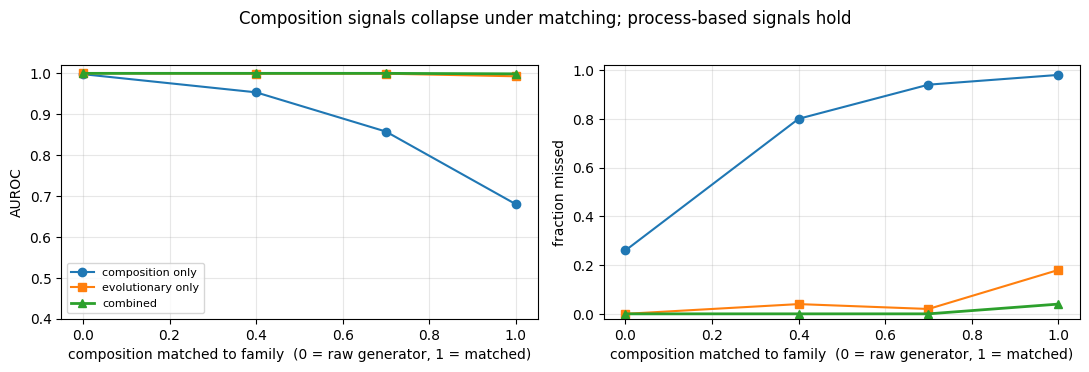

figure saved to /content/drive/MyDrive/mpnn_detect/runs/run1/stress_test.png


In [12]:
# Same numbers as a picture.
import matplotlib.pyplot as plt

blends = [r[0] for r in rows]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (label, idx) in enumerate([("AUROC", 0), ("fraction missed", 1)]):
    ax[i].plot(blends, [r[1][idx] for r in rows], "o-", label="composition only")
    ax[i].plot(blends, [r[2][idx] for r in rows], "s-", label="evolutionary only")
    ax[i].plot(blends, [r[3][idx] for r in rows], "^-", label="all signals", lw=2)
    ax[i].set_xlabel("composition matched to family  (0 = raw generator, 1 = matched)")
    ax[i].set_ylabel(label)
    ax[i].grid(alpha=0.3)
ax[0].set_ylim(0.4, 1.02); ax[1].set_ylim(-0.02, 1.02); ax[0].legend(fontsize=8)
plt.suptitle("Composition signals collapse under matching; process-based signals hold", y=1.02)
plt.tight_layout()
plt.savefig(OUT / "stress_test.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"figure saved to {OUT / 'stress_test.png'}")

### Not knowing the generator at all

The composition signals above assume you know which model you are looking for —
and the shipped fingerprints are approximate priors, not measurements. So what
happens if you drop every signal that depends on one?

`generator_agnostic=True` keeps only the signals that ask whether the sequence
could have descended from the family: coupling violation, substitution
implausibility, tree violation, indel deficit, rate incongruence, orphan fold,
and a fingerprint-free drift test. None of them references a generator.

In [13]:
unregistered = md.GeneratorFingerprint(
    name="unregistered",
    freqs=np.random.default_rng(5).dirichlet(np.ones(20) * 3),
)

md.LOG.setLevel(logging.ERROR)
cases = {
    "ProteinMPNN-like": md.simulate_designed(profile, n=50, seed=3),
    "composition-matched": md.simulate_designed(profile, n=50, composition_blend=1.0, seed=3),
    "a generator we have no fingerprint for":
        md.simulate_designed(profile, n=50, fingerprint=unregistered, seed=9),
}
controls = ref_set[:50]

print(f"{'designs from':<40} | {'assumes ProteinMPNN':>21} | {'generator-agnostic':>21}")
print(f"{'':<40} | {'AUROC  missed':>21} | {'AUROC  missed':>21}")
print("-" * 90)
agnostic_rows = []
for label, sims in cases.items():
    cells = []
    for agnostic in (False, True):
        d = md.Detector(profile=profile, alpha=0.01, generator_agnostic=agnostic)
        d.fit_null(null_set)
        nat = [d.predict(s).score for s in controls]
        des = [d.predict(s) for s in sims]
        a = auroc(nat, [r.score for r in des])
        m = sum(1 for r in des if r.p_value > 0.01) / len(des)
        cells.append((a, m))
    agnostic_rows.append({"designs_from": label,
                          "fingerprint_auroc": round(cells[0][0], 4),
                          "fingerprint_missed": round(cells[0][1], 4),
                          "agnostic_auroc": round(cells[1][0], 4),
                          "agnostic_missed": round(cells[1][1], 4)})
    f = lambda c: f"{c[0]:.3f}  {100*c[1]:4.0f}%"
    print(f"{label:<40} | {f(cells[0]):>21} | {f(cells[1]):>21}")
md.LOG.setLevel(_prev)

md.write_csv(agnostic_rows, str(OUT / "generator_agnostic.csv"))
print()
print("Dropping the fingerprint costs little and removes the dependency on a")
print("prior nobody has validated. On a generator with no fingerprint, it wins.")

designs from                             |   assumes ProteinMPNN |    generator-agnostic
                                         |         AUROC  missed |         AUROC  missed
------------------------------------------------------------------------------------------
ProteinMPNN-like                         |          1.000     0% |          1.000     0%
composition-matched                      |          1.000     4% |          1.000     0%


INFO mpnn_detect: Wrote 3 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/generator_agnostic.csv


a generator we have no fingerprint for   |          0.999     4% |          1.000     0%

Dropping the fingerprint costs little and removes the dependency on a
prior nobody has validated. On a generator with no fingerprint, it wins.


## 13. Which signals are carrying the result

Reported as net pull — the mean contribution to a design minus the mean
contribution to a natural sequence. This is the right diagnostic, not
per-signal AUROC: a signal can rank perfectly backwards yet be scaled to
near-zero influence, which is exactly what happens to signals the detector
decides cannot discriminate on this family.

In [14]:
Rn = [detector.predict(s) for s in evaluation]
Rd = [detector.predict(s) for s in md.simulate_designed(profile, n=50, seed=5)]
keys = [s.key for s in Rn[0].signals]
Cn = np.array([[s.contribution for s in r.signals] for r in Rn])
Cd = np.array([[s.contribution for s in r.signals] for r in Rd])

pulls = sorted(((Cd[:, i].mean() - Cn[:, i].mean(), k) for i, k in enumerate(keys)),
               reverse=True)
print(f"{'signal':<26} {'net pull':>9}   layer")
print("-" * 54)
rows = []
for pull, k in pulls:
    # The layer is carried on the signal's own spec. A hand-written lookup here
    # had quietly filed the phylogenetic placement signals under "composition".
    layer = md.SPEC_BY_KEY[k].layer
    print(f"{k:<26} {pull:>+9.2f}   {layer}")
    rows.append({"signal": k, "net_pull": round(float(pull), 4),
                 "mean_natural": round(float(Cn[:, keys.index(k)].mean()), 4),
                 "mean_designed": round(float(Cd[:, keys.index(k)].mean()), 4),
                 "layer": layer})
md.write_csv(rows, str(OUT / "signal_contributions.csv"))

print()
for layer in ("composition", "structural", "covariation", "evolutionary", "phylogenetic"):
    tot = sum(r["net_pull"] for r in rows if r["layer"] == layer)
    n = sum(1 for r in rows if r["layer"] == layer)
    if n:
        print(f"  {layer:<14} {n:>2} signals, total pull {tot:+.2f}")


INFO mpnn_detect: Simulated 50 proteinmpnn-like redesigns.
INFO mpnn_detect: Wrote 19 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/signal_contributions.csv


signal                    net pull   layer
----------------------------------------------------
coupling_violation           +5.65   covariation
orphan_fold                  +4.30   structural
exposed_llr                  +3.25   structural
equilibrium_drift            +2.91   evolutionary
comp_llr_family              +2.28   composition
stratum_contrast             +2.05   structural
directional_drift            +1.71   evolutionary
subst_implausibility         +1.65   evolutionary
charge_excess                +1.42   composition
tree_violation               +1.14   evolutionary
indel_deficit                +0.94   evolutionary
variable_llr                 +0.35   structural
rate_incongruence            +0.23   evolutionary
hydrophobic_moment           +0.10   composition
low_complexity               +0.03   composition
construct_motifs             +0.00   composition
kmer_repeat                  -0.01   composition
rare_depletion               -0.08   composition
cys_depletion       

'/content/drive/MyDrive/mpnn_detect/runs/run1/signal_contributions.csv'

## 14. Real ProteinMPNN output

Everything above this point scored **simulated** designs. `simulate_designed`
samples from the same profile the detector scores against and tilts the
composition with the same fingerprint the detector tests for, so it cannot
produce a design whose failure mode the detector does not already model. Those
numbers bound performance from above; they do not measure it.

This section runs the real thing. It clones ProteinMPNN, downloads real kinase
catalytic-domain backbones, generates sequences, and feeds them back through
the same detector. Three controls make the comparison mean something:

1. **The native record is skipped.** ProteinMPNN writes the input sequence as
   the first record of every output file. It is a natural sequence. Counting it
   as a design puts a guaranteed miss in the design set.
2. **The backbones' own native sequences are scored separately.** If those are
   called designed, the detector is separating *domain fragments* from *whole
   proteins*, not designs from naturals.
3. **Both classes are cut to the aligned domain.** A backbone is one domain
   carved out of a larger protein — the TYK2 catalytic domain is 288 residues,
   TYK2 is 1,187. Comparing bare domains against whole proteins measures domain
   context, so `md.extract_domains` trims the natural class the same way.

On CPU this takes roughly two minutes per backbone per temperature. A GPU
runtime (Runtime → Change runtime type → T4) makes it close to instant.

In [ ]:
#@title Generate real designs { display-mode: "form" }
RUN_PROTEINMPNN = True  #@param {type:"boolean"}
BACKBONES = "tyk2,cmet,p38,syk,cdk2,cdk8"  #@param {type:"string"}
N_PER_BACKBONE = 30  #@param {type:"integer"}
SAMPLING_TEMPS = "0.1 0.2 0.3"  #@param {type:"string"}
MODEL_VARIANTS = "vanilla,soluble"  #@param {type:"string"}

import csv, os, subprocess, urllib.request

PMPNN_DIR = pathlib.Path("/content/ProteinMPNN")
BB_DIR = OUT / "backbones"
GEN_DIR = OUT / "designs"          # on Drive, so a re-run skips generation
BB_DIR.mkdir(parents=True, exist_ok=True)
GEN_DIR.mkdir(parents=True, exist_ok=True)

# Backbones come from the OpenFF protein-ligand benchmark rather than RCSB:
# these files are prepared structures with complete N/CA/C/O backbones, which
# is what ProteinMPNN needs. A PDB straight from RCSB often has missing loop
# atoms, and ProteinMPNN will silently design across the gap.
BB_URL = ("https://raw.githubusercontent.com/openforcefield/"
          "protein-ligand-benchmark/main/data/{}/01_protein/crd/protein.pdb")
#@markdown All six are protein kinases (PF00069), so they are in the same
#@markdown family as the profile built above. Chain A is the kinase in each;
#@markdown cdk2 and cdk8 also carry a cyclin chain, which is held fixed and
#@markdown used as context exactly as a real design job would.

names = [b.strip() for b in BACKBONES.split(",") if b.strip()]
variants = [v.strip() for v in MODEL_VARIANTS.split(",") if v.strip()]

# These backbones are kinases. Measuring them against a profile built from
# anything else - above all the simulated fallback family - compares two
# unrelated families and produces a high detection rate that means nothing.
# Say so and stop, rather than printing a number that looks like a result.
FAMILY_IS_REAL = SOURCE != "simulated"
if not FAMILY_IS_REAL:
    print("The family above is SIMULATED, because UniProt could not be")
    print("reached. The backbones below are real kinases, so a detection rate")
    print("measured against a simulated profile would be measuring 'different")
    print("family', not 'designed'. Skipping. Re-run section 4 once UniProt is")
    print("reachable, or pass natural_fasta=<your own FASTA> to run offline.")
    RUN_PROTEINMPNN = False

if RUN_PROTEINMPNN:
    if not PMPNN_DIR.exists():
        print("cloning ProteinMPNN (the weights are in the repo)...")
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/dauparas/ProteinMPNN",
                        str(PMPNN_DIR)], check=True,
                       capture_output=True)
    try:
        import torch
        dev = "GPU" if torch.cuda.is_available() else "CPU"
    except ImportError:
        raise SystemExit("ProteinMPNN needs PyTorch; Colab ships it by default.")
    print(f"ProteinMPNN ready, running on {dev}")

    for name in names:
        pdb = BB_DIR / f"{name}.pdb"
        if not pdb.exists():
            urllib.request.urlretrieve(BB_URL.format(name), pdb)
        n_ca = sum(1 for l in pdb.read_text().splitlines()
                   if l.startswith("ATOM") and l[12:16].strip() == "CA")
        for variant in variants:
            out_dir = GEN_DIR / variant
            if (out_dir / "seqs" / f"{name}.fa").exists():
                print(f"  {name}/{variant}: already on Drive, skipping")
                continue
            out_dir.mkdir(parents=True, exist_ok=True)
            cmd = ["python", str(PMPNN_DIR / "protein_mpnn_run.py"),
                   "--pdb_path", str(pdb), "--pdb_path_chains", "A",
                   "--out_folder", str(out_dir),
                   "--num_seq_per_target", str(N_PER_BACKBONE),
                   "--sampling_temp", SAMPLING_TEMPS,
                   "--seed", "37", "--batch_size", "1"]
            if variant == "soluble":
                cmd.append("--use_soluble_model")
            t0 = time.time()
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode != 0:
                print(f"  {name}/{variant}: FAILED\n{r.stderr[-600:]}")
                continue
            print(f"  {name}/{variant}: {n_ca} residues, "
                  f"{N_PER_BACKBONE * len(SAMPLING_TEMPS.split())} designs "
                  f"in {time.time() - t0:.0f}s")

# Read whatever is on Drive, whether this run generated it or an earlier one did.
try:
    if not FAMILY_IS_REAL:
        raise md.SequenceError("family is simulated; see above")
    gens = md.load_generator_output([str(GEN_DIR / v) for v in variants],
                                    include_native=True)
except md.SequenceError as exc:
    print(f"No generator output available: {exc}")
    gens = []

real_designs = [g for g in gens if not g.is_native]
# One native per backbone. ProteinMPNN writes the native into every output
# folder, so reading two model variants yields each native twice; the control
# then reports "2 of 12" where it means "1 of 6", and double-weights whichever
# backbone is flagged.
real_natives, _seen_bb = [], set()
for g in gens:
    if g.is_native and g.source not in _seen_bb:
        _seen_bb.add(g.source)
        real_natives.append(g)
assert all(isinstance(g, md.GeneratedSequence) for g in real_designs), (
    "real_designs must hold GeneratedSequence objects from a real run - "
    "simulated sequences must never reach this section")
if real_designs:
    print()
    print(md.describe_generator_output(real_designs))
    print()
    print(f"plus {len(real_natives)} native backbone sequences, held aside as a control")

### What ProteinMPNN's composition actually looks like

`PROTEINMPNN_PRIOR` was set from published descriptions of de novo designs:
strong E/K/A/L/R enrichment, near-total cysteine avoidance. That describes
designed *helical bundles*. It does not necessarily describe ProteinMPNN
redesigning a natural backbone, which has to satisfy that backbone's burial
pattern — and redesign of a real protein is the more realistic threat.

Measure it instead of assuming it.

In [ ]:
if real_designs:
    emp = md.composition("".join(g.sequence.seq for g in real_designs))
    nat = md.composition("".join(s.seq for s in evaluation))
    prior = md.PROTEINMPNN_PRIOR.freqs

    print(f"{'aa':<4}{'measured':>10}{'prior':>9}{'natural':>10}"
          f"{'meas/nat':>10}{'prior/nat':>11}")
    print("-" * 56)
    wrong = []
    for i, a in enumerate(md.AA):
        m, p, q = emp[i], prior[i], nat[i]
        flag = "" if (m - q) * (p - q) > 0 else "  <- prior points the wrong way"
        if (m - q) * (p - q) <= 0 and abs(m - q) > 0.004:
            wrong.append(a)
        print(f"{a:<4}{m:>10.4f}{p:>9.4f}{q:>10.4f}"
              f"{m / q:>10.2f}{p / q:>11.2f}{flag}")
    print()
    print(f"prior disagrees in direction on: {', '.join(wrong) or 'nothing'}")

    # Fit a fingerprint on the real output and register it next to the prior.
    fp_real = md.fit_fingerprint("proteinmpnn_measured",
                                 [g.sequence.seq for g in real_designs])
    md.register_fingerprint(fp_real)
    print(f"\nregistered '{fp_real.name}' from {len(real_designs)} real designs "
          f"({fp_real.confidence})")
    print("Measured on these backbones only - ProteinMPNN's output composition")
    print("follows the structure it is given, so refit this on your own targets.")

### Detection, measured

Three numbers, and the order matters. The false-positive rate on natural
kinases says whether the threshold is honest. The native-backbone rate says
whether the comparison is fair. Only then does the detection rate on designs
mean anything.

In [ ]:
if real_designs:
    # Fair comparison: trim the natural class to the same aligned domain the
    # designs are. Without this the detector can win on domain context.
    nat_domains = md.extract_domains(profile, evaluation, min_coverage=0.6)
    det_real = md.Detector(profile=profile, fingerprint=fp_real,
                           alpha=detector.alpha)
    # Domain extraction drops whatever does not cover the profile, so THIS
    # null is smaller than section 7's and may not reach the alpha section 7
    # settled on. Adopt what this null can actually place, or every p-value
    # here comes from the tail fit - the previous run inherited alpha=0.0515
    # against an 84-sequence null whose floor was 0.0588 and warned about it.
    info_real = det_real.fit_null(md.extract_domains(profile, null_set,
                                                     min_coverage=0.6))
    rec = info_real.get("recommended_alpha")
    if rec and rec > det_real.alpha:
        print(f"this null holds {info_real['n']} sequences, so alpha="
              f"{det_real.alpha:g} is below its floor; using {rec:.4g}")
        det_real.alpha = round(rec, 4)

    # Which of these backbones actually belong to the profiled family? A
    # backbone that does not produces a detection rate that is partly just
    # distance. On the six kinase backbones against a PF00069 family built
    # from whole UniProt entries of 150-400 aa, three are small Ser/Thr
    # kinases with 98-99% identical relatives in the family and three are
    # tyrosine kinases with only 34-39% - and the second group's designs came
    # out at 100%, 100%, 100% against 91%, 98%, 100% for the first.
    membership, mem_stats = md.backbone_membership(profile, real_natives)
    print(md.describe_backbone_membership(membership, mem_stats))
    print()
    IN_FAMILY = {m.source for m in membership if m.in_family}

    r_nat = [det_real.predict(s) for s in nat_domains]
    r_des = [det_real.predict(g.sequence) for g in real_designs]
    r_bb = [det_real.predict(g.sequence) for g in real_natives]
    a = det_real.alpha

    rate = lambda rs: sum(1 for r in rs if r.p_value <= a) / max(len(rs), 1)
    print(f"alpha = {a}")
    print(f"{'class':<38}{'n':>5}{'called designed':>18}")
    print("-" * 61)
    print(f"{'natural kinase domains':<38}{len(r_nat):>5}{rate(r_nat):>17.1%}"
          f"   <- false positives")
    print(f"{'the backbones own native sequences':<38}{len(r_bb):>5}"
          f"{rate(r_bb):>17.1%}   <- must also stay low")
    print(f"{'REAL ProteinMPNN designs':<38}{len(r_des):>5}"
          f"{rate(r_des):>17.1%}   <- the measurement")
    print()
    print(f"AUROC natural vs designed: "
          f"{md._auroc([r.score for r in r_nat], [r.score for r in r_des]):.4f}")

    # The restricted number is the one to report when some backbones are out
    # of family: the pooled rate above mixes in designs whose detection owes
    # something to the backbone being distant rather than designed.
    if IN_FAMILY and len(IN_FAMILY) < len({g.source for g in real_designs}):
        kept = [g for g in real_designs if g.source in IN_FAMILY]
        dropped = sorted({g.source for g in real_designs} - IN_FAMILY)
        r_in = [det_real.predict(g.sequence) for g in kept]
        print(f"Restricted to the {len(IN_FAMILY)} in-family backbone(s) "
              f"({', '.join(sorted(IN_FAMILY))}), excluding "
              f"{', '.join(dropped)}:")
        print(f"  {len(kept)} designs, {rate(r_in):.1%} detected   "
              f"<- report THIS, not the pooled rate above")
        print()

    if rate(r_bb) > 2 * max(rate(r_nat), 0.02):
        # Two very different causes, and the profile match distinguishes them:
        # a backbone from another family barely matches the profile at all,
        # while a same-family domain matches well and is flagged for its
        # boundaries. Naming the wrong one sends you to fix the wrong thing.
        cov = [profile.score(g.sequence).coverage for g in real_natives]
        bits = [profile.score(g.sequence).bits_per_position for g in real_natives]
        print()
        print("WARNING: the backbones' own native sequences are being called")
        print(f"designed ({rate(r_bb):.0%}) far more often than other naturals")
        print(f"({rate(r_nat):.0%}). The detection rate above is NOT a clean")
        print("measurement of design. Mean profile coverage of those natives: "
              f"{np.mean(cov):.0%}, {np.mean(bits):.2f} bits/position.")
        flagged = [g for g in real_natives
                   if det_real.predict(g.sequence).p_value <= a]
        distant = [m for m in membership
                   if not m.in_family and m.source in {g.source for g in flagged}]
        if np.mean(cov) < 0.6 or np.mean(bits) < 0.3:
            print()
            print("They barely match the profile, so these backbones are not in")
            print("the family it was built from. Use backbones from the family")
            print("you profiled, or profile the family the backbones belong to.")
        elif distant:
            # The cause that coverage cannot see. These natives align fine and
            # are not fragments; they are simply distant WITHIN the family.
            print()
            print("They align well and are not fragments, so this is subfamily")
            print("distance: " + ", ".join(
                f"{m.source} at {m.identity:.0%} identity" for m in distant)
                  + " against a family whose own members sit at "
                  f"{mem_stats['mean']:.0%}.")
            print("Report the in-family restricted rate printed above; these")
            print("backbones are on a different part of the kinase tree than")
            print("the profile covers.")
        else:
            print()
            print("They match the profile well and are not distant within it,")
            print("so this is domain context: the designs are bare domains and")
            print("the natural class is not. Raise min_coverage in")
            print("extract_domains, or build the family from extracted domains.")

    print()
    print(md.detection_by_group(det_real, real_designs, by="source"))
    print()
    print(md.detection_by_group(det_real, real_designs, by="temperature"))
    print()
    print(md.detection_by_group(det_real, real_designs, by="run"))

### The validation report that is a measurement, not a bound

`cross_validate` takes `designed_sequences=`. Pass the real output and every
per-signal AUROC in the report refers to real designs. The report records which
it was, so a saved CSV cannot be mistaken for the other.

The designs are split into disjoint folds, one per repeat. Scoring the same
fixed set on every repeat and pooling the scores would feed the permutation
test ten copies of each sequence and make every p-value look small.

In [ ]:
report_real = None
if real_designs and THOROUGH:
    t0 = time.time()
    report_real = md.cross_validate(
        md.extract_domains(profile, family, min_coverage=0.6),
        n_repeats=VALIDATION_REPEATS,
        alpha=EFFECTIVE_ALPHA,
        fingerprint=fp_real,
        designed_sequences=[g.sequence for g in real_designs],
        coupling_method=COUPLING_METHOD,
        symfrac=SYMFRAC,
        seed=3,
    )
    print(report_real.report())
    with open(OUT / "validation_real.csv", "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(report_real.to_rows()[0]))
        w.writeheader()
        w.writerows(report_real.to_rows())
    print(f"\nwrote {OUT / 'validation_real.csv'} in {time.time()-t0:.0f}s")
elif real_designs:
    print("Set THOROUGH = True to run the repeated-split validation on the")
    print("real designs. It is the only number here that comes with an interval.")

## 15. Repeated-split validation

Every number above comes from **one** split of **one** family. A single number
has no error bar, so there is no way to tell a signal that works from one that
got lucky — and no way to know whether the false-positive rate you set is the
one you are getting.

This rebuilds everything — profile, couplings, evolutionary model, placement
null, per-family references, score null — on independent splits and reports each
signal's AUROC with an interval across rebuilds plus a label-permutation
p-value. It is the most expensive cell in the notebook and the one that makes
the rest defensible.

Measured on a simulated family of 2,500, 8 splits took **354 s** and showed
something a single split cannot: the false-positive rate averaged 0.6% at
α = 0.01 but its interval reached **2.6%**, and four signals turned out to carry
no evidence at all on that family — one of them pointing the wrong way.

In [ ]:
if THOROUGH:
    report = md.cross_validate(
        family,
        n_repeats=VALIDATION_REPEATS,
        alpha=EFFECTIVE_ALPHA,
        symfrac=SYMFRAC,
        coupling_method=COUPLING_METHOD,
        n_designed=60,
        n_permutations=2000,
        seed=7,
    )
    print()
    print(report.report())
    md.write_csv(report.to_rows(), str(OUT / "validation.csv"))

    dead = [s.key for s in report.signals if not s.informative]
    if dead:
        print()
        print("Signals not usable on this family:")
        for k in dead:
            s = next(x for x in report.signals if x.key == k)
            print(f"   {k:<26} AUROC {s.auroc_mean:.3f} "
                  f"[{s.auroc_lo:.2f},{s.auroc_hi:.2f}]  p={s.permutation_p:.3f}"
                  f"   {s.verdict}")
        print()
        print("Now use that. Two things are wrong with hand-set weights here:")
        print("a signal below chance pulls against the rest, and even a harmless")
        print("one adds variance to the aggregate, which widens the natural null")
        print("and raises the threshold - so detection falls while AUROC stays")
        print("high. Zeroing the dead ones fixes the first; scaling every weight")
        print("by its measured separation fixes both.")
        detector.apply_validation(report, drop_uninformative=True, reweight=True)
        detector.save(str(DETECTOR_PATH))
        print()
        print(f"   {len(detector.validation_info['kept'])} signals kept, "
              f"{len(detector.validation_info['dropped'])} zeroed, "
              f"{len(detector.validation_info.get('reweighted', {}))} rescaled")
        print("   (this prunes the detector for THIS family - a signal dead on")
        print("    kinases may be the one that fires on another fold)")
        print()
        print("   Note the weights are now estimated from the same simulated")
        print("   designs the report used, so they inherit that bound too.")
else:
    report = None
    print("skipped (THOROUGH is off) - the numbers above have no error bars")

In [ ]:
# Section 12 showed hand-set weights losing to the evolutionary signals alone
# on composition-matched designs. Now that the validation report exists, redo
# that comparison with weights rescaled by measured separation.
if THOROUGH and report is not None:
    md.LOG.setLevel(logging.ERROR)

    def stress(weights, sims, validated=None):
        d = md.Detector(profile=profile, weights=dict(weights),
                        bias=md.DEFAULT_BIAS, alpha=EFFECTIVE_ALPHA)
        d.calibrated = False
        if validated is not None:
            d.apply_validation(validated, drop_uninformative=True, reweight=True)
        d.fit_null(null_set)
        nat = [d.predict(s).score for s in evaluation]
        des = [d.predict(s) for s in sims]
        return (auroc(nat, [r.score for r in des]),
                sum(1 for r in des if r.p_value > EFFECTIVE_ALPHA) / len(des))

    EVO_ONLY = {k: (v if md.SPEC_BY_KEY[k].layer in ("evolutionary", "phylogenetic")
                    else 0.0) for k, v in md.DEFAULT_WEIGHTS.items()}
    print(f"{'matched':>8} | {'prior weights':>18} | {'evolutionary only':>18} | "
          f"{'pruned + reweighted':>20}")
    print(f"{'':>8} | {'AUROC   missed':>18} | {'AUROC   missed':>18} | "
          f"{'AUROC   missed':>20}")
    print("-" * 74)
    reweight_rows = []
    for blend in (0.0, 0.5, 1.0):
        sims = md.simulate_designed(profile, n=50, composition_blend=blend, seed=13)
        a = stress(md.DEFAULT_WEIGHTS, sims)
        e = stress(EVO_ONLY, sims)
        b = stress(md.DEFAULT_WEIGHTS, sims, validated=report)
        reweight_rows.append({"composition_blend": blend,
                              "prior_auroc": round(a[0], 4), "prior_missed": round(a[1], 4),
                              "evo_only_auroc": round(e[0], 4),
                              "evo_only_missed": round(e[1], 4),
                              "reweighted_auroc": round(b[0], 4),
                              "reweighted_missed": round(b[1], 4)})
        f = lambda r: f"{r[0]:.3f}  {100*r[1]:5.0f}%"
        print(f"{blend:>8.1f} | {f(a):>18} | {f(e):>18} | {f(b):>20}")
    md.write_csv(reweight_rows, str(OUT / "reweighting.csv"))
    md.LOG.setLevel(logging.INFO)
    print()
    print("Reweighting recovers most of the gap between the hand-weighted")
    print("detector and the evolutionary signals alone. Measured on 3,544 real")
    print("kinases over 8 design samples it ties that column rather than")
    print("beating it (-0.6%, winning 3 of 8), so on composition-matched")
    print("designs the composition signals add nothing even when rescaled -")
    print("what rescaling fixes is the damage they were doing.")
    print()
    print("The weights come from the same simulated designs the report scored,")
    print("so they are not independent evidence - they are a better use of a")
    print("measurement already made. Counter-intuitively, a report computed on")
    print("HARDER designs makes them worse (7 of 8 paired samples): the report")
    print("ranks signals, and harder designs estimate that ranking less well.")

In [ ]:
if THOROUGH and report is not None:
    import matplotlib.pyplot as plt

    sig = sorted(report.signals, key=lambda s: s.auroc_mean)
    ys = np.arange(len(sig))
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(sig) + 1.2))
    for i, s in enumerate(sig):
        colour = "#2563eb" if s.informative else "#9ca3af"
        ax.plot([s.auroc_lo, s.auroc_hi], [i, i], color=colour, lw=2.2,
                solid_capstyle="round")
        ax.plot(s.auroc_mean, i, "o", color=colour, ms=5)
    ax.axvline(0.5, color="#dc2626", ls="--", lw=1, zorder=0)
    ax.set_yticks(ys)
    ax.set_yticklabels([s.key for s in sig], fontsize=8)
    ax.set_xlabel("AUROC (bar = 90% interval across independent rebuilds)")
    ax.set_xlim(0.3, 1.02)
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"Per-signal performance over {report.n_repeats} rebuilds\n"
                 "grey = interval spans chance, so the signal carries no evidence here",
                 fontsize=9)
    plt.tight_layout()
    plt.savefig(OUT / "validation.png", dpi=150, bbox_inches="tight")
    plt.show()

### Reweighting from real output, versus from simulated

Section 15 derived signal weights from a report built on **simulated** designs.
A report built that way rewards the signals the simulator was built to trip.
Section 14 produced a report on **real** output. Compare the two: where they
disagree, the simulated report was tuning the detector for a generator that
does not exist.

In [ ]:
if report_real is not None:
    print(f"{'signal':<26}{'layer':<14}{'real AUROC':>12}"
          f"{'simulated':>12}   change")
    print("-" * 78)
    sim = ({s.key: s.auroc_mean for s in report.signals}
       if 'report' in dir() and report is not None else {})
    for s in sorted(report_real.signals, key=lambda s: -s.auroc_mean):
        old = sim.get(s.key)
        delta = "" if old is None else f"{s.auroc_mean - old:+.3f}"
        print(f"{s.key:<26}{md.SPEC_BY_KEY[s.key].layer:<14}"
              f"{s.auroc_mean:>12.3f}"
              f"{(f'{old:.3f}' if old is not None else '-'):>12}   {delta}")

    n_real = sum(s.informative for s in report_real.signals)
    print(f"\n{n_real}/{len(report_real.signals)} signals informative against "
          f"real output", end="")
    if sim:
        n_sim = sum(s.informative for s in report.signals)
        print(f", versus {n_sim}/{len(report.signals)} against simulated.")
    else:
        print(".")

    detector_real = md.Detector(profile=profile, fingerprint=fp_real,
                                alpha=EFFECTIVE_ALPHA)
    detector_real.apply_validation(report_real, drop_uninformative=True,
                                   reweight=True)
    info_dr = detector_real.fit_null(md.extract_domains(profile, null_set,
                                                        min_coverage=0.6))
    rec_dr = info_dr.get("recommended_alpha")
    if rec_dr and rec_dr > detector_real.alpha:
        detector_real.alpha = round(rec_dr, 4)
        print(f"saved detector runs at alpha={detector_real.alpha:g}, the "
              f"smallest its {info_dr['n']}-sequence null can place")
    detector_real.save(str(OUT / "detector_real.json"))
    print(f"\nsaved a detector weighted by the real report to detector_real.json")

## 16. Screening at scale

Everything so far answers "is this a designed member of family X". A screen is
handed a sequence and does not know X. A `ScreeningLibrary` holds one calibrated
detector per family and routes each query to whichever profile recognises it.

The part that matters for safety is what happens when nothing recognises it. A
sequence no profile matches has **not been cleared — it has not been assessed**,
and reporting those as negatives is how a screen quietly fails. The library
flags them `no_family_match` and says so in the result.

In [16]:
library = md.ScreeningLibrary(
    fallback=md.Detector(profile=None, generator_agnostic=True)
)
library.add(SOURCE, detector)
# Add a detector per family you care about; each needs its own null.
# library.add("PF00071", other_detector)

queries = list(ref_set[:60]) + md.simulate_designed(profile, n=20, seed=11)
rng = np.random.default_rng(0)
queries.append(md.CleanSequence(
    seq="".join(md.AA[i] for i in rng.integers(0, 20, 230)), name="unrelated_sequence"))

results = library.predict_many(queries, fdr=0.05)
routed = sum(1 for r in results if r.family)
unmatched = [r for r in results if "no_family_match" in r.flags]
flagged = [r for r in results if r.fdr_significant]

print(f"  {len(results)} screened")
print(f"  {routed} routed to a family, {len(unmatched)} not assessed")
print(f"  {len(flagged)} flagged at FDR 5%")
print()
for r in sorted(flagged, key=lambda r: r.q_value)[:5]:
    print(f"    {r.name:<28} family={r.family}  q={r.q_value:.3g}")
if unmatched:
    print()
    print(f"  NOT ASSESSED: {', '.join(r.name for r in unmatched)}")
    print("  These are not negatives. Add the relevant family and re-screen.")

md.write_csv(md.results_to_rows(results), str(OUT / "library_screen.csv"))
library.save(str(OUT / "library"))

INFO mpnn_detect: Simulated 20 proteinmpnn-like redesigns.
INFO mpnn_detect: FDR 0.05: 20 of 80 flagged (per-sequence alpha would flag 20).
INFO mpnn_detect: Wrote 81 rows to /content/drive/MyDrive/mpnn_detect/runs/run1/library_screen.csv
INFO mpnn_detect: Profile saved to /content/drive/MyDrive/mpnn_detect/runs/run1/library/simulated/profile_model
INFO mpnn_detect: Library of 1 families saved to /content/drive/MyDrive/mpnn_detect/runs/run1/library


  81 screened
  80 routed to a family, 1 not assessed
  20 flagged at FDR 5%

    sim_proteinmpnn_0016         family=simulated  q=2.71e-08
    sim_proteinmpnn_0014         family=simulated  q=7.84e-08
    sim_proteinmpnn_0011         family=simulated  q=1.01e-07
    sim_proteinmpnn_0018         family=simulated  q=3.45e-07
    sim_proteinmpnn_0004         family=simulated  q=4.5e-07

  NOT ASSESSED: unrelated_sequence
  These are not negatives. Add the relevant family and re-screen.


## 17. What was written

Everything below is already on Drive — nothing here needs re-running to keep it.
Re-running this notebook with the same `RUN_NAME` reuses the saved profile and
detector; change `RUN_NAME` to start a clean run alongside the old one.

In [17]:
import shutil

def human(n):
    for unit in ("B", "KB", "MB", "GB"):
        if n < 1024 or unit == "GB":
            return f"{n:,.0f} {unit}" if unit == "B" else f"{n:.1f} {unit}"
        n /= 1024

print(f"{OUT}")
print()
total = 0
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        size = path.stat().st_size
        total += size
        rel = path.relative_to(OUT)
        print(f"  {str(rel):<42} {human(size):>10}")
print()
print(f"  {'total':<42} {human(total):>10}")
print()
print(f"cache (shared across runs): {human(sum(f.stat().st_size for f in CACHE.rglob('*') if f.is_file()))}")

if not ON_DRIVE:
    print()
    print("NOT on Drive - this folder disappears when the runtime ends.")
    print("Re-run the mount cell, or download the zip below.")

shutil.make_archive(str(OUT.parent / f"{RUN_NAME}_results"), "zip", str(OUT))
print()
print(f"zipped: {OUT.parent / (RUN_NAME + '_results.zip')}")

/content/drive/MyDrive/mpnn_detect/runs/run1

  batch_summary.csv                               270 B
  detector.json                                 13.1 KB
  generator_agnostic.csv                          214 B
  library/library.json                             74 B
  library/simulated/detector.json               13.1 KB
  library/simulated/profile_model/coupling.npz   140.3 KB
  library/simulated/profile_model/evolution.npz   190.7 KB
  library/simulated/profile_model/family.hmm    99.1 KB
  library/simulated/profile_model/members.fasta.gz    21.3 KB
  library/simulated/profile_model/members.npz    20.6 KB
  library/simulated/profile_model/profile.json     1.7 KB
  library_screen.csv                            23.7 KB
  profile_model/coupling.npz                   140.3 KB
  profile_model/evolution.npz                  190.7 KB
  profile_model/family.hmm                      99.1 KB
  profile_model/members.fasta.gz                21.3 KB
  profile_model/members.npz                 

### Loading a saved run later

In a new session, mount Drive and point at the same folder — no rebuild needed:

```python
import mpnn_detect as md, pathlib
from google.colab import drive; drive.mount('/content/drive')

OUT = pathlib.Path('/content/drive/MyDrive/mpnn_detect/runs/run1')
profile  = md.FamilyProfile.load(str(OUT / 'profile_model'))
detector = md.Detector.load(str(OUT / 'detector.json'), profile=profile)

print(detector.predict("MKLSKEDFLKAVEKG...").report())
```

The saved profile carries the HMM, its members, the per-family reference
distributions, the covariation model and the evolutionary model. The saved
detector carries the weights, the null and the window null — so the
false-positive rate you set is restored exactly, not re-estimated.

## Limits

Worth being blunt about, since the point of replacing the original was that it
looked like it worked when it did not.

* **`simulate_designed()` cannot validate the fingerprint it assumes.** It
  draws from the same prior the detector tests for, so separation is partly
  guaranteed. The validation report says so in its own notes. Every AUROC from
  sections 1-13 is an **upper bound**. Section 14 runs real ProteinMPNN and
  replaces those bounds with measurements — run it.
* **The shipped composition prior disagrees with real ProteinMPNN output in
  direction** on D, G, P, W and Y: it was taken from published descriptions of
  de novo helical bundles, and redesigning a natural backbone is a different
  distribution. `PROTEINMPNN_MEASURED` is measured on real output, but only at
  T ≤ 0.3 on six kinase backbones, and it *loses* to the vague prior on T ≥ 0.5
  output from the same tool. Fingerprint your own generator at the temperature
  you expect, or run `generator_agnostic=True` and drop those signals entirely.
* **Measured detection is six proteins, not 1,080 sequences.** 98.2% came from
  1,080 real designs over six kinase backbones; the honest error bar is the
  worst-to-best backbone spread (89%-100%), because designs from one backbone
  share whatever that structure does to the signals.
* **Read the native-backbone control before believing any detection rate.**
  Section 14 scores the designs' own native sequences as a separate class. A
  run that flagged half of those reported 99.9% detection and was measuring
  sequence length, not design.
* **The simulator resamples positions independently.** Real ProteinMPNN
  conditions on structure, so it *will* reproduce backbone-dictated couplings
  and some exchangeability that these tests never challenge. The coupling and
  evolutionary signals are therefore flattered most by the simulation.
* **DCA needs data.** Mean-field inversion wants the effective sequence count
  well above the number of model positions; below that it declines and falls
  back to mutual information, which counts transitive correlations. A small
  family gets the weaker model, and the build log says which one it used.
* **Placement is local and approximate.** Neighbour-joining on the nearest ~16
  relatives with Fitch reconstruction at the root is not a full maximum-
  likelihood placement on a family-wide tree. It is calibrated leave-one-out
  against real members, which is what makes it interpretable.
* **Tail-extrapolated p-values are approximate.** Past the null's empirical
  floor of 1/(n+1), p-values come from an exponential tail fit. With a
  few-hundred-sequence null the measured false-positive rate at α = 0.01 ranged
  up to 2.6%. More null sequences is the only real fix.
* **A screen is only as broad as its library.** `no_family_match` means not
  assessed, not negative.
* **A pipeline tuned against a detector defeats that detector.** This is a
  screen, not a security boundary, and not a biosecurity control.

The module is written to `mpnn_detect.py` in the working directory (folder icon,
left sidebar) — readable, editable, downloadable.